# Search a Trade Space

This example demonstrates how to search a trade space of constellation designs for Pareto-efficient designs with the `tatc.tradespace` module: declaring a hierarchical design space, evaluating designs in replicates (in parallel, with a cache of the analysis of each satellite), finding the Pareto-efficient designs and what drives them, screening designs with a cheaper analysis, and searching the space with optimizers (Optuna and pymoo, installed with `pip install tatc[tradespace]`).

The trade is a sampling problem of a pre-Phase A study: how many satellites, in how many orbit planes (each of which needs its own launch), sample the Earth sufficiently often? A point is **sufficiently sampled** if an imager observes it at least four times in a day, and the objective is the share of points that are. A second objective measures sufficiency by its purpose: a point is **accurately sampled** if the mean of its samples estimates the daily mean of a field that varies within hours (such as convective precipitation) with an error of at most half the field's standard deviation. The points are a random sample of the Earth (a lattice of points in a random orientation), so the share is a statistical estimate: each replicate of a design draws a different sample of points, which is the uncertainty of the estimate.

The examples that follow take the same trade further: ranking designs with the uncertainty of their replicates (`RankUncertainDesigns`), comparing them across scenarios (`CompareScenarios`), trading their cost and utility (`TradeCostAndUtility`), and planning their deployment and failures (`PlanMissions`). They import the design space and study of this example from `trade_space_example.py`, beside the notebooks.

## Configure the Analysis

The analysis covers one day, with 100 points in each of five replicates. A design may have at most 10 satellites.

In [1]:
from datetime import datetime, time as time_of_day, timedelta, timezone
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

START = datetime(2026, 7, 1, tzinfo=timezone.utc)
DURATION = timedelta(days=1)  # the period of the analysis
N_POINTS = 100  # points sampled in each replicate
N_REPLICATES = 5  # replicates (samples of points) of each design
SAMPLES_PER_DAY = 4  # a point is sufficiently sampled if it is observed at least this often
MAX_SATELLITES = 10
DECORRELATION_TIME = timedelta(hours=3)  # of the field whose daily mean is estimated
MAX_RELATIVE_ERROR = 0.5  # a point is accurately sampled within this share of the field's standard deviation

## Define the Design Space

A `DesignSpace` declares the design variables, in the order they are decided. Every design has an altitude and an imager's field of regard, and a layout that is one of two alternatives (a `Choice`), each declared with a building block of the `tatc.tradespace` module:

* a **Walker delta** constellation (`walker_space`), with an inclination, a number of planes, a number of satellites in each plane, and the relative spacing of the satellites between planes (whose upper bound depends on the number of planes), or
* one or two **sun-synchronous** planes (`sso_planes_space`, a `Repeat` of planes), each with its own equator crossing time and number of satellites. The planes are unordered: two planes in either order are the same design. A constraint of the building block requires the planes to have different crossing times (otherwise, they would be the same plane).

The points sampled in each replicate are an `Uncertain` parameter (the seed of a random orientation of a lattice of points, `Uncertain.seed`), drawn for each replicate rather than designed, as are the failures of satellites and the growth of the cost of developing the satellites (both used in the examples that follow). The replicates use common random numbers: every design samples the same points in the same replicate, so that differences between designs are not differences between their samples. The points of a replicate are a Fibonacci lattice in a random orientation (`generate_points_rotated_lattice`): each point is as likely to fall anywhere as a random point, but the points cover the Earth evenly rather than clustering by chance, so that the shares of points vary less between replicates than with random points (`generate_points_random`; here, with 1.5 to 4 times less variance), and fewer replicates estimate them as precisely. The decorrelation time of the field whose daily mean is estimated is a `Fixed` value of the design space, which the metrics read from each design, rather than a constant of the metrics, so that scenarios can change it (see `CompareScenarios`).

The constraint on the number of satellites returns the number in excess of the limit (a number that is not positive if the design satisfies it), rather than `True` or `False`, so that optimizers can tell how far an infeasible design is from a feasible one.

In [2]:
from tatc.tradespace import (
    Categorical,
    Choice,
    DesignSpace,
    Fixed,
    Integer,
    Real,
    Uncertain,
    count_satellites,
    sso_planes_space,
    walker_space,
)

space = DesignSpace(
    altitude=Real(500e3, 800e3, step=100e3),
    field_of_regard=Categorical([30, 60]),
    layout=Choice(
        walker=walker_space(inclination=Real(45, 75, step=15), planes=Integer(1, 4), per_plane=Integer(1, 4)),
        sso=sso_planes_space(crossing=Real(6, 18, step=3), satellites=Integer(1, 2), count=Integer(1, 2)),
    ),
    points_seed=Uncertain.seed(),
    failure_seed=Uncertain.seed(),
    cost_growth=Uncertain(lambda rng: float(rng.triangular(0.9, 1.0, 1.6))),  # of development, for cost risk
    decorrelation_time=Fixed(DECORRELATION_TIME),  # of the field, which scenarios may change (see CompareScenarios)
    epoch=Fixed(START),  # the start of the analysis, which may be drawn for each replicate (see PlanMissions)
    constraints=[lambda d: count_satellites(d.layout) - MAX_SATELLITES],
)
designs = space.enumerate()
print(f"{len(designs)} feasible designs of {len(space.unit_paths())} decisions")

1096 feasible designs of 12 decisions


## Define the Study

An `ObservationStudy` evaluates each design in each replicate: it builds the design's satellites (`build`, with `build_constellation`, which builds the satellites of either layout with a payload: here, an imager, but also entries of the instrument catalog), collects their observations of the replicate's targets (`Observations`), and computes the metrics of the observations (`sample`). The targets are the points of a randomly oriented lattice, generated in each replicate from its seed (`Targets`, from the design's uncertain `points_seed`). The observations of each satellite are cached on disk: designs share many satellites (the same orbit and imager, if not the same name), whose observations are computed once, by the parallel worker processes of the study (`n_jobs=-1`, one per processor), and kept between sessions. A `ResultStore` keeps the records of the evaluations in a file, so that running the notebook again (or resuming it after an interruption) takes them from the file rather than evaluating them again. Both are keyed by the definition of the study (its fingerprint), which describes the points by the recipe that generates them and the code of TAT-C that the study uses: a changed study evaluates its designs again, and a study whose code changed says why. Variants of the study (of other periods, replicates, or scenarios) share the store, whose fingerprints keep their evaluations apart.

The metrics are the two objectives: the share of points with at least four samples a day, and the share whose sampling error (`tatc.analysis.estimate_sampling_error`, for an exponential correlation in time with a decorrelation time of 3 hours) is at most half the field's standard deviation. The study also records the numbers of satellites and of orbit planes (of the design's `layout`), and plans the deployment of each design and estimates its life-cycle cost (`MissionPlan`, of a `DeploymentSchedule` and a `CostModel`, used in `TradeCostAndUtility` and `PlanMissions`).

`study.replace` makes variants of the study with some of its arguments replaced, such as a cheaper study of a shorter period for screening (below), or studies of the phases of deployment and of failures (`PlanMissions`).

In [3]:
from functools import partial

from tatc.analysis import estimate_sampling_error
from tatc.generation import generate_points_rotated_lattice
from tatc.schemas import Instrument
from tatc.tradespace import (
    CostModel,
    DeploymentSchedule,
    LaunchCost,
    MissionPlan,
    ObservationStudy,
    Observations,
    OperationsCost,
    ResultStore,
    SatelliteCost,
    Targets,
    build_constellation,
)

# the deployment of each design: 3 years of development, a production line of 4 satellites a year, launches of up to 3
# satellites at most every half year, and 5 years of operations from the first launch
SCHEDULE = DeploymentSchedule(years=5, development_years=3, production_rate=4, launch_interval=0.5, launch_capacity=3)
# illustrative costs (millions of dollars), not estimates of any mission: satellites with an imager of each field of
# regard, small launchers, and operations, discounted at 3% a year
COST_MODEL = CostModel(
    satellites={
        30: SatelliteCost(development=40, first_unit=12, learning_rate=0.9, mass=60),
        60: SatelliteCost(development=60, first_unit=18, learning_rate=0.9, mass=90),
    },
    launch=LaunchCost(per_launch=8),
    operations=OperationsCost(per_year=3, per_satellite_year=0.5),
    discount_rate=0.03,
)

# the deployment and cost of each design: satellites of the kind of its field of regard, with its growth of
# development costs
PLAN = MissionPlan(SCHEDULE, COST_MODEL, kind="field_of_regard", growth={"development": "cost_growth"})
# the points of each replicate: a randomly oriented lattice, generated from the replicate's seed
TARGETS = Targets(generate_points_rotated_lattice, N_POINTS, seed="points_seed")
CACHE_DIRECTORY = Path(tempfile.gettempdir()) / "tatc-search-trade-space"


def sample(observations, design, duration=DURATION):
    """The shares (%) of points sampled sufficiently and accurately by observations over a duration from the design's
    epoch (of the field of the design's decorrelation time)."""
    if len(observations) == 0:  # no satellites
        return {"sufficient": 0.0, "accurate": 0.0}
    samples = observations.groupby("target_hash").size()
    error = estimate_sampling_error(observations, design.epoch, design.epoch + duration, design.decorrelation_time)
    threshold = SAMPLES_PER_DAY * duration / timedelta(days=1)
    return {
        "sufficient": 100 * (samples >= threshold).sum() / N_POINTS,
        "accurate": 100 * (error.relative_error <= MAX_RELATIVE_ERROR).sum() / N_POINTS,
    }


def build(d):
    """The satellites of a design: an imager of its field of regard in each orbit of its layout."""
    imager = Instrument(name="imager", field_of_regard=d.field_of_regard)
    return build_constellation(d.layout, imager, epoch=START, altitude=d.altitude)


# the study of the shares (%) of points sampled sufficiently and accurately over the period by the satellites of each
# design, and of its deployment and cost (by the mission plan), whose evaluations are kept in a store
study = ObservationStudy(
    space,
    build,
    Observations(TARGETS, "epoch", DURATION, directory=CACHE_DIRECTORY),
    sample,
    layout="layout",
    plan=PLAN,
    replicates=N_REPLICATES,
    n_jobs=-1,
    store=ResultStore(CACHE_DIRECTORY / "results.sqlite"),
)

OBJECTIVES = {"satellites": "min", "planes": "min", "sufficient": "max"}
REFERENCE = {"satellites": MAX_SATELLITES + 1, "planes": 5, "sufficient": 0}  # worse than every design, for hypervolumes

## Evaluate Every Design

The design space is small enough to evaluate every design, which gives the true Pareto front against which the screening and the searches below are compared. `summarize` gives a summary of the designs: a row per design, with its values (from which `DesignSpace.designs_of` rebuilds it) and the mean of each objective over the replicates (and its standard deviation and standard error), and `pareto_front` the designs that no other design is as good as in every objective and better than in one.

In [4]:
from tatc.tradespace import hypervolume, pareto_front, summarize

results = study.run(designs)
print(f"{len(results)} evaluations: {len(designs)} designs x {N_REPLICATES} replicates")

# a row per design: its values and the means of its objectives over the replicates (with their standard deviations and
# standard errors), and whether it is efficient
summary = summarize(results, list(OBJECTIVES))
summary["pareto"] = pareto_front(summary, OBJECTIVES)
exact_hypervolume = hypervolume(summary, OBJECTIVES, REFERENCE)


def describe(d):
    """A short description of a design (a row of its values)."""
    if d.layout == "walker":
        layout = (
            f"Walker {d['layout.walker.inclination']:.0f} deg: {d['layout.walker.planes']:.0f} x "
            f"{d['layout.walker.per_plane']:.0f} (spacing {d['layout.walker.relative_spacing']:.0f})"
        )
    else:
        planes = [
            f"{d[f'layout.sso.planes[{k}].satellites']:.0f} at {d[f'layout.sso.planes[{k}].crossing']:02.0f}:00"
            for k in range(int(d['layout.sso.planes.count']))
        ]
        layout = "SSO: " + ", ".join(planes)
    return f"{d.altitude / 1e3:.0f} km, {d.field_of_regard} deg FOR, {layout}"


summary["description"] = summary.apply(describe, axis=1)
front = summary[summary.pareto].sort_values(["satellites", "planes"])
front[["description", "satellites", "planes", "sufficient", "sufficient se"]].round(1)

5480 evaluations: 1096 designs x 5 replicates


,description,satellites,planes,sufficient,sufficient se
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.2,0.9
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,16.6,1.2
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.2,2.2
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,38.0,1.2
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,68.2,1.8
965,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,69.6,0.8
1025,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.8,0.2


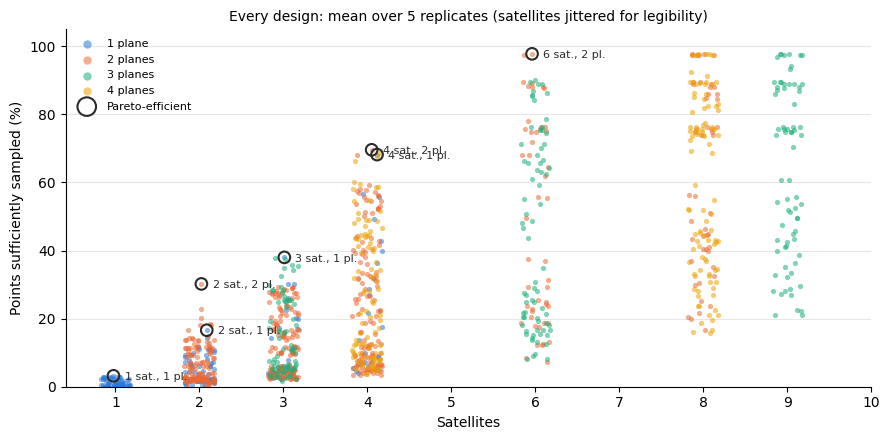

In [5]:
from tatc.tradespace import plot_designs


def planes_name(planes):
    """The name of a number of planes."""
    return f"{planes:.0f} plane{'s' if planes > 1 else ''}"


ax = plot_designs(
    summary,
    "satellites",
    "sufficient",
    by="planes",
    front="pareto",
    labels=lambda row: f"{row.satellites:.0f} sat., {row.planes:.0f} pl.",
    names=planes_name,
    jitter=0.18,  # satellites, for legibility
    legend="upper left",
)
ax.set(
    xlabel="Satellites",
    ylabel="Points sufficiently sampled (%)",
    xticks=range(1, MAX_SATELLITES + 1),
    ylim=(0, 105),
)
ax.set_title("Every design: mean over 5 replicates (satellites jittered for legibility)", fontsize=10)
ax.figure.tight_layout()
plt.show()

Of the 1,096 feasible designs, seven are Pareto-efficient (ringed in the figure). All of them fly at the highest altitude (800 km) with the wider field of regard (60 degrees), which observe the most points per satellite, so the trade is in the number of satellites and planes. One satellite samples only 3% of the points sufficiently (at least four times a day), and the share rises steeply with the number of satellites: two satellites in two planes (30%) sample nearly twice as many points as two in one plane (17%), four satellites sample about two thirds of the points in one plane or two (68% and 70%), and six satellites in two inclined planes sample 98%. No design with more than six satellites is efficient, because six already sample nearly every point. Designs with the same number of satellites differ widely: their layout (inclination, planes, and phasing) matters as much as their number.

## Measure the Sampling Error

Four samples a day count the same whether they come hours apart or minutes apart, but they do not estimate a daily mean equally well: samples closer together than the field's decorrelation time repeat each other. The share of points accurately sampled measures what the samples are for. The table gives the efficient designs by this objective (with the numbers of satellites and planes, as before), and the figure compares the two objectives for every design.

In [6]:
ACCURACY = {"satellites": "min", "planes": "min", "accurate": "max"}
accuracy = summarize(results, ["satellites", "planes", "sufficient", "accurate"])
accuracy["description"] = accuracy.apply(describe, axis=1)
accuracy["pareto"] = pareto_front(accuracy, ACCURACY)
accuracy[accuracy.pareto].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient", "accurate", "accurate se"]
].round(1)

,description,satellites,planes,sufficient,accurate,accurate se
1050,"800 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.0,4.2,0.6
1047,"800 km, 60 deg FOR, SSO: 2 at 06:00",2.0,1.0,11.6,10.4,0.9
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.2,34.2,1.8
1019,"800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...",3.0,1.0,26.2,17.0,1.1
1075,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3.0,2.0,28.8,60.6,1.3
1001,"800 km, 60 deg FOR, Walker 60 deg: 3 x 1 (spac...",3.0,3.0,34.2,61.0,3.8
1020,"800 km, 60 deg FOR, Walker 75 deg: 1 x 4 (spac...",4.0,1.0,49.2,28.6,2.1
1081,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4.0,2.0,57.6,85.4,0.7
758,"700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6.0,3.0,89.0,96.4,0.5
1045,"800 km, 60 deg FOR, Walker 75 deg: 4 x 2 (spac...",8.0,4.0,97.8,96.6,0.5


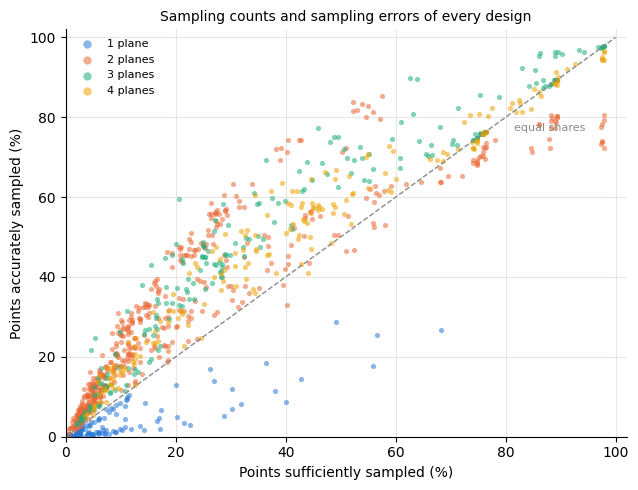

In [7]:
from tatc.tradespace import style_axes
from tatc.tradespace.plotting import GRAY

fig, ax = plt.subplots(figsize=(6.5, 5))
plot_designs(accuracy, "sufficient", "accurate", by="planes", names=planes_name, legend="upper left", ax=ax)
ax.plot([0, 100], [0, 100], color=GRAY, lw=1, ls="--")
ax.annotate("equal shares", (80, 80), xytext=(6, -10), textcoords="offset points", fontsize=8, color=GRAY)
ax.set(xlabel="Points sufficiently sampled (%)", ylabel="Points accurately sampled (%)", xlim=(0, 102), ylim=(0, 102))
style_axes(ax, grid="both")
ax.set_title("Sampling counts and sampling errors of every design", fontsize=10)
fig.tight_layout()
plt.show()

The revisits of two designs of four satellites, those in one plane that sample the most points sufficiently and those that sample the most points accurately, show why they differ in accuracy: the times between their samples (`tatc.analysis.compute_revisit_statistics`), including the longest gap of the day, and the times of day they sample (`tatc.analysis.compute_local_time_coverage`, in eight 3-hour intervals of local time).

In [8]:
from tatc.analysis import compute_local_time_coverage, compute_revisit_statistics

four = accuracy[(accuracy.satellites == 4)].sort_values("sufficient", ascending=False)
# the most sufficiently sampling design of four satellites in one plane, and the most accurately sampling design of four
first = four[four.planes == 1].iloc[0]
second = four.sort_values("accurate", ascending=False).iloc[0]
rows = []
# the designs of the rows, rebuilt from their values
for row, design in zip((first, second), space.designs_of(four, [first.design, second.design])):
    # the observations of the design's first replicate, and its points
    observations = study.observations_of(design)
    points = study.targets_of(design)
    revisits = compute_revisit_statistics(observations, START, START + DURATION, targets=points)
    local = compute_local_time_coverage(observations, targets=points)
    observed = revisits[revisits.samples > 0]
    rows.append(
        {
            "design": row.description,
            "sufficient (%)": row.sufficient,
            "accurate (%)": row.accurate,
            "median revisit (h)": observed["revisit p50"].dt.total_seconds().median() / 3600,
            "median longest gap (h)": revisits.max_gap.dt.total_seconds().median() / 3600,
            "median 3-h intervals sampled": local.local_bins_sampled.median(),
        }
    )
pd.DataFrame(rows).set_index("design").round(1)

,sufficient (%),accurate (%),median revisit (h),median longest gap (h),median 3-h intervals sampled
design,,,,,
"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spacing 0)",68.2,26.8,0.4,13.8,2.0
"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",57.6,85.4,5.9,7.6,4.0


Counting samples and measuring their sampling error rank designs differently. Satellites in one plane (blue in the figure) sample many points four times a day, but in bursts: consecutive passes of satellites that follow each other in a plane, minutes apart, repeat each other for a field that decorrelates in hours. Four satellites in one Walker plane sample 68% of the points at least four times a day, but only 27% accurately: half of their revisits are 0.4 hours apart, and they leave a gap of 13.8 hours. Four satellites in two sun-synchronous planes sample fewer points four times (58%) but 85% accurately: their samples are 5.9 hours apart, in four of the eight 3-hour intervals of the day. Designs in a single plane remain efficient only as those that need the fewest launches, and sample at most 29% of the points accurately; six satellites in three planes sample 96% of the points accurately, nearly as many as nine (98%).

## Find What Drives the Objectives

`sensitivity` gives the share of the variance of each objective (over the designs, by their means over the replicates) that each design variable explains, among the designs in which the variable is active: the variables of the Walker layout apply only to Walker designs, and those of the sun-synchronous layout only to theirs. The shares are adjusted for the variance that the levels of a variable would explain by chance, which matters for samples of designs and for variables of many levels.

In [9]:
from tatc.tradespace import sensitivity

# the summary keeps the values of each design
variables = [
    "altitude",
    "field_of_regard",
    "layout",
    "layout.walker.inclination",
    "layout.walker.planes",
    "layout.walker.per_plane",
    "layout.walker.relative_spacing",
    "layout.sso.planes.count",
]
sensitivity(accuracy, variables, ["sufficient", "accurate"]).round(2)

,sufficient,accurate,active
variable,,,
field_of_regard,0.25,0.25,1.00
layout.walker.per_plane,0.22,0.18,0.64
layout,0.19,0.12,1.00
layout.walker.planes,0.12,0.29,0.64
layout.sso.planes.count,0.10,0.19,0.36
altitude,0.03,0.03,1.00
layout.walker.relative_spacing,0.03,0.06,0.64
layout.walker.inclination,0.00,0.00,0.64


The field of regard explains the most of both objectives (25% of their variance), as it sets the swath of every satellite. The layout matters next, but differently for the two objectives: the number of satellites in each Walker plane explains more of the share of points sufficiently sampled (22%) than of those accurately sampled (18%), and the number of Walker planes the reverse (12% and 29%), as more planes spread the samples in time. The altitude explains little of either objective (3%), although a higher orbit widens the swath: its effect is small next to those of the field of regard and the layout. The inclination explains nothing on average over the Walker designs.

## Screen Designs with a Cheaper Analysis

Evaluating every design is affordable here, but not for larger spaces or longer analyses. `screen` evaluates every design with a cheap study, keeps the best (whole fronts, until it keeps at least `keep` of them), and evaluates only those with the full study. A cheap study ranks designs less exactly, so criteria of the cheap study with a tolerance of an objective (`Criteria`) keep designs that are within it of the front of the cheap study.

The cheap study must rank designs as the full study would. Here, the screening study analyzes one replicate, rather than five, over a shorter period, with the threshold of sufficient sampling scaled to the period: 12 hours with two observations, or 6 hours with one. The table compares each screening's front with the true front (how many of its efficient designs it keeps, and its hypervolume), and its cost (the satellites analyzed times the days of their analyses) with that of evaluating every design.

In [10]:
from tatc.tradespace import Criteria, screen


def over(duration):
    """The study of one replicate over a shorter period, as a cheap analysis."""
    return study.replace(
        observations=Observations(TARGETS, "epoch", duration, directory=CACHE_DIRECTORY),
        metrics=partial(sample, duration=duration),
        replicates=1,
    )


full_cost = results.satellites.sum() * DURATION / timedelta(days=1)  # satellite-days of analysis
true_front = set(summary.design[summary.pareto])
screenings = []
for hours, keep, tolerance in [(12, 0.05, None), (12, 0.1, 5.0), (6, 0.05, None), (6, 0.2, None)]:
    # the criteria of the cheap study, with a tolerance of its share, if any, and of the full study
    cheap = OBJECTIVES if tolerance is None else Criteria(OBJECTIVES, tolerance={"sufficient": tolerance})
    screening = screen([over(timedelta(hours=hours)), study], [cheap, OBJECTIVES], designs, keep=keep)
    # the satellite-days of the analyses of each stage
    days = screening.results.stage.map({0: hours / 24, 1: DURATION / timedelta(days=1)})
    screenings.append(
        {
            "screening study": f"{hours} h, 1 replicate",
            "keep (%)": 100 * keep,
            "tolerance (%)": tolerance,
            "designs kept": len(screening.designs),
            "efficient designs kept": f"{len(true_front & {d.key for d in screening.designs})} of {len(true_front)}",
            "hypervolume (% of true front)": 100 * hypervolume(screening.summary, OBJECTIVES, REFERENCE) / exact_hypervolume,
            "cost (% of every design)": 100 * (screening.results.satellites * days).sum() / full_cost,
        }
    )
pd.DataFrame(screenings).round(1)

,screening study,keep (%),tolerance (%),designs kept,efficient designs kept,hypervolume (% of true front),cost (% of every design)
0,"12 h, 1 replicate",5.0,NaN,74,4 of 7,98.8,16.9
1,"12 h, 1 replicate",10.0,5.0,248,7 of 7,100.0,29.2
2,"6 h, 1 replicate",5.0,NaN,62,1 of 7,83.0,10.6
3,"6 h, 1 replicate",20.0,NaN,231,5 of 7,96.6,25.1


The 12-hour screening study ranks designs nearly as the full study does. Keeping the best 5% of the designs finds a front with 99% of the hypervolume of the true front at 17% of the cost of evaluating every design, although it misses three of the seven efficient designs, whose places designs with nearly the same objectives take. Keeping 10%, with a tolerance of 5 percentage points, keeps every efficient design at 29% of the cost.

The 6-hour screening study is cheaper, but ranks designs differently: one observation of a point in 6 hours separates designs less than four observations in a day do. Keeping 5% of the designs keeps only one of the seven efficient ones (83% of the hypervolume), and keeping 20% still misses two of them (97% of the hypervolume) at 25% of the cost, nearly as much as the 12-hour study that keeps them all. How many designs to keep depends on how well the cheap study ranks designs, which is worth checking on a sample of designs evaluated with both studies before screening a larger space.

## Search with Optimizers

Larger design spaces cannot be enumerated or even screened, and an optimizer searches them for efficient designs instead. `optimize_optuna` suggests designs with Optuna's trials, which search the hierarchical design space directly (`DesignSpace.suggest`), and records the violation of the constraint of each infeasible design, which Optuna's samplers use to prefer feasible designs. `optimize_pymoo` searches the unit hypercube that encodes the design space (`DesignSpace.decode`) with a pymoo algorithm, which eliminates the proposals of designs proposed or evaluated before: many points of the hypercube decode to the same design (those in the same level of each variable, or that differ only in the variables of a branch not chosen), which pymoo's own elimination of equal points does not see. Both evaluate each design once, however often it is proposed, and evaluate the designs proposed together in parallel. A search chooses its front from one evaluation of each design, which favors designs whose replicates were lucky: its results (a `Search`) are refined and confirmed as for any study (see `RankUncertainDesigns`).

Each search below is given a budget of about 200 proposals, and is compared with a Latin hypercube sample of 200 designs (`DesignSpace.sample`). The designs evaluated (and the analyses of their satellites) are those of the evaluation of every design above, so they are retrieved from the cache.

In [11]:
import optuna
from pymoo.algorithms.moo.nsga2 import NSGA2

from tatc.tradespace import hypervolume_progress, optimize_optuna, optimize_pymoo

optuna.logging.set_verbosity(optuna.logging.WARNING)
BUDGET = 200
searches = {}
searches["Optuna (NSGA-II)"] = optimize_optuna(
    study,
    OBJECTIVES,
    n_trials=BUDGET,
    sampler=optuna.samplers.NSGAIISampler(population_size=20, seed=1),
    batch_size=20,
).results
searches["pymoo (NSGA-II)"] = optimize_pymoo(
    study, OBJECTIVES, NSGA2(pop_size=20), ("n_gen", BUDGET // 20), seed=1
).results
searches["Latin hypercube sample"] = study.run(space.sample(BUDGET, method="lhs", seed=1))

# the hypervolume (% of the true front's) of the designs evaluated, as designs are evaluated
progress = {
    name: 100 * hypervolume_progress(search_results, OBJECTIVES, REFERENCE) / exact_hypervolume
    for name, search_results in searches.items()
}
pd.DataFrame(
    {
        name: {
            "designs evaluated": search_results.design.nunique(),
            "hypervolume (% of true front)": progress[name].iloc[-1],
        }
        for name, search_results in searches.items()
    }
).T.round(1)

,designs evaluated,hypervolume (% of true front)
Optuna (NSGA-II),143.0,92.1
pymoo (NSGA-II),166.0,100.0
Latin hypercube sample,176.0,79.3


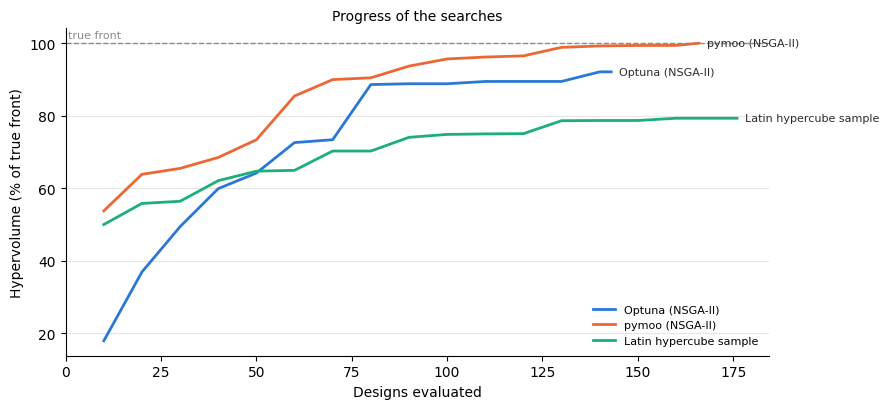

In [12]:
from tatc.tradespace import plot_progress

ax = plot_progress(progress)
ax.axhline(100, color=GRAY, lw=1, ls="--")
ax.annotate("true front", (0, 100), xytext=(2, 4), textcoords="offset points", fontsize=8, color=GRAY)
ax.set(ylabel="Hypervolume (% of true front)")
ax.set_title("Progress of the searches", fontsize=10)
ax.figure.tight_layout()
plt.show()

Both optimizers find more of the hypervolume than a Latin hypercube sample of as many designs. Optuna (NSGA-II, searching the hierarchical space directly) finds 92% of the hypervolume of the true front with 143 designs, 13% of the space. pymoo (NSGA-II, searching the encoded space) finds all of it with 166 designs: it proposes no design twice, and its other 34 proposals violate the constraint on the number of satellites (without eliminating duplicates by design, its 200 proposals encoded only 75 designs, which found 88%). The sample finds 79% with 176 designs. The searches stop at their budget of proposals, not at convergence: a larger budget, or screening, would bring Optuna's closer to the true front. Their results also depend on their seeds (over eight seeds, pymoo's search finds 88 to 100% of the hypervolume, 96.5% on average), so compare several seeds before relying on one.

## Summary

* A `DesignSpace` declares a hierarchical trade space, with choices between alternatives (`Choice`), repeated elements such as orbit planes (`Repeat`), bounds that depend on other variables, constraints that measure their violation, and uncertain parameters (`Uncertain`) drawn for each replicate. Building blocks declare common constellation layouts (`walker_space` and `sso_planes_space`) and build their satellites with instruments or entries of the instrument catalog (`build_constellation`).
* An `ObservationStudy` (a `Study` of the observations of `Targets`, with a `MissionPlan` of deployment and costs) evaluates designs in replicates (here, of points of a randomly oriented lattice, `generate_points_rotated_lattice`, which vary less between replicates than random points), in parallel, with a cache of `Observations` that analyzes each distinct satellite once and a `ResultStore` that keeps its evaluations (by the fingerprint of the study, which describes its targets and the code of TAT-C it uses, so that a changed study evaluates its designs again). Every design of a space of about a thousand designs can be evaluated in minutes, and `Study.replace` makes variants of a study.
* A summary of the results (`summarize`, or `aggregate`) has a row per design, with its values, for `pareto_front` and `plot_designs`. Statistical sufficiency is measured by the sampling error of the statistic that observations estimate (`tatc.analysis.estimate_sampling_error`), which counts of samples overstate when samples cluster in time, as they do in a single plane; revisit statistics and local time coverage explain it. `sensitivity` finds the design variables that drive each objective.
* `screen` evaluates every design with a cheap study and the best with the full one, which finds the front at a fraction of the cost if the cheap study ranks designs as the full one does.
* `optimize_optuna` and `optimize_pymoo` search spaces too large to enumerate, and find most of the front with a fraction of the designs (`hypervolume_progress`), pymoo's proposing no design twice (by design, not by point of the encoded space). `plot_designs` and `plot_progress` plot the designs, with the efficient ones ringed, and the progress of searches.

The examples that follow take the trade further: ranking designs with the uncertainty of their replicates (`RankUncertainDesigns`), comparing them across scenarios (`CompareScenarios`), trading their cost and utility (`TradeCostAndUtility`), and planning their deployment and failures (`PlanMissions`).

The sampling error here is that of a model of the field (an exponential correlation in time with a decorrelation time of 3 hours); with a simulation of the field (a nature run), `tatc.analysis.sample_field` and `compare_sampled_means` measure it directly. The uncertainty here is that of the sample of points; others (such as the phase of the satellites or the period of the analysis) are further `Uncertain` parameters of the design space.